# Étape 4 — Classification : « quel type d'avion ? »

**Objectif :** entraîner un réseau de neurones qui reconnaît le **type d'avion**
(A1 à A20) à partir d'une **vignette** (étape 2). C'est le deuxième étage de notre
système.

| Choix | Pourquoi |
|---|---|
| **ResNet-18**, un réseau de neurones convolutif (CNN) | les couches de convolution repèrent des motifs (bords, formes, ailes) de plus en plus complexes |
| **pré-entraîné sur ImageNet** (1,2 million de photos) | il sait déjà « voir » : on ne remplace que sa dernière couche, pour qu'elle sorte nos 20 types. C'est du **transfer learning** |
| **data augmentation** | rotations, retournements, cadrage et luminosité au hasard : le réseau apprend ce qui définit un type plutôt que d'apprendre les images par cœur |
| **la macro-F1** comme mesure principale | la moyenne des F1 de chaque type : un type rare (A6) compte autant qu'un type fréquent (A16) |

Comme pour le détecteur, l'entraînement a été fait sur **Google Colab**. La cellule
d'entraînement est désactivée par défaut, et ce notebook re-mesure le modèle entraîné
sur la **validation**, sur le processeur.

Pré-requis : l'étape 2 (le dossier `data/crops/`).

## Pour relancer sur Google Colab (facultatif)

En local, la cellule suivante ne fait rien. Sur Colab, avec une carte graphique, c'est
ainsi que nos modèles ont été entraînés :
1. copier le dossier du projet dans le Drive, sous `Mon Drive/projet_avions` ;
2. ouvrir le notebook dans Colab (Exécution > Modifier le type d'exécution > GPU) ;
3. lancer d'abord l'étape 2, qui prépare `data/yolo/` et `data/crops/` sur Colab ;
4. dans les étapes 3 et 4, exécuter la cellule ci-dessous, puis mettre `ENTRAINER = True`.

In [1]:
import os
import sys

SUR_COLAB = "google.colab" in sys.modules
if SUR_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/projet_avions/etapes")
else:
    print("Exécution locale : rien à faire.")

Exécution locale : rien à faire.


## 0. Préparation

In [2]:
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.models import ResNet18_Weights, resnet18
from torchvision.transforms import v2

# Le notebook se lance depuis le dossier etapes/ : la racine du projet est le dossier parent
RACINE = Path.cwd().parent
CROPS_DIR = RACINE / "data" / "crops"  # les vignettes de l'étape 2
MODELS_DIR = RACINE / "models"  # poids finaux de nos modèles
RUNS_DIR = RACINE / "runs"  # sorties des entraînements (courbes, métriques)
assert (CROPS_DIR / "index.csv").exists(), "Lancer d'abord l'étape 2 (préparation)"

# Les 20 types d'avions, dans l'ordre NUMÉRIQUE (un tri alphabétique donnerait A1, A10, A11...
# et les numéros de classe seraient décalés sans erreur visible)
CLASSES = [f"A{i}" for i in range(1, 21)]
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASSES)}

# Les mêmes réglages qu'à l'étape 2, pour les vignettes
CROP_SCALE = 2.0  # côté du carré / plus grand côté de la boîte
CROP_SIZE = 256  # taille des vignettes, en pixels
PAD_VALUE = 128  # gris neutre

## 1. Les vignettes en entrée

Une vignette par avion annoté, déjà rangée par jeu à l'étape 2. Le tableau `index.csv`
donne, pour chacune, son fichier et son type (`label` : numéro de 0 à 19).

split
train    6295
test      788
val       787


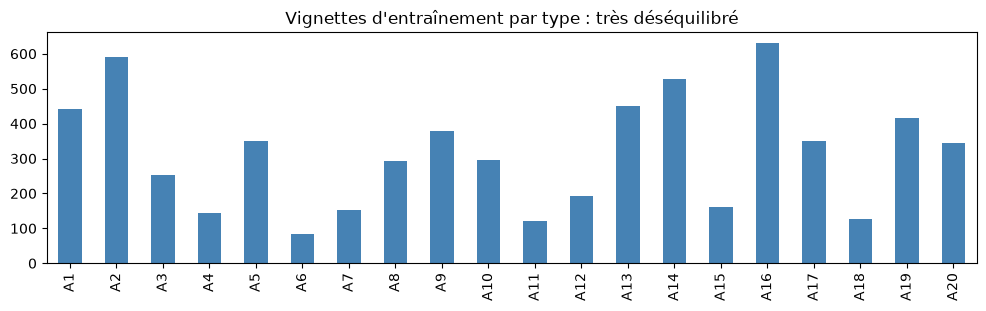

In [3]:
def load_crops_index(split: str | None = None) -> pd.DataFrame:
    """Lit data/crops/index.csv (une ligne par vignette), éventuellement filtré sur un jeu."""
    index = pd.read_csv(CROPS_DIR / "index.csv", dtype={"image_id": str})
    return index if split is None else index[index["split"] == split].reset_index(drop=True)


class CropDataset(Dataset):
    """Les vignettes d'un jeu, lues sur le disque une par une : (image transformée, type)."""

    def __init__(self, index: pd.DataFrame, transform):
        self.paths = index["crop_path"].tolist()
        self.labels = index["label"].tolist()
        self.transform = transform

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, i: int):
        image = Image.open(CROPS_DIR / self.paths[i]).convert("RGB")
        return self.transform(image), self.labels[i]


index = load_crops_index()
par_type = pd.crosstab(index["class_name"], index["split"]).reindex(CLASSES)
print(index["split"].value_counts().to_string())
ax = par_type["train"].plot.bar(figsize=(12, 3), color="steelblue")
ax.set_title("Vignettes d'entraînement par type : très déséquilibré")
ax.set_xlabel("")
plt.show()

## 2. La data augmentation

À chaque passage sur une vignette d'entraînement, on la modifie **au hasard** :

| Transformation | Pourquoi |
|---|---|
| rotation de 0 à 360° | vu du ciel, un avion peut pointer dans toutes les directions |
| retournements gauche-droite et haut-bas | même raison |
| cadrage un peu plus large ou plus serré, un peu décalé | imite les boîtes imparfaites du détecteur, que le classifieur recevra dans l'application |
| ± 20 % de luminosité et de contraste | la luminosité varie beaucoup d'une image à l'autre (étape 1) |

Pour la validation, le test et l'application, **pas de hasard** : un cadrage fixe au
centre, à 1,2 × la boîte de l'avion. Dans les deux cas, la vignette finit en
224 × 224 px, la taille attendue par le ResNet-18.

In [4]:
IMAGE_SIZE = 224  # taille d'entrée des réseaux pré-entraînés sur ImageNet
# Moyenne et écart-type des pixels d'ImageNet : les poids pré-entraînés ont appris avec ces valeurs
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
# Dans une vignette de 256 px (carré de 2 × la boîte), la boîte de l'avion mesure 128 px
BOX_SIDE = CROP_SIZE / CROP_SCALE
EVAL_CROP_FACTOR = 1.2  # cadrage fixe : 1,2 × la boîte, un peu de marge autour de l'avion


def _to_normalized_tensor() -> list:
    return [
        v2.Resize(IMAGE_SIZE, antialias=True),
        v2.ToDtype(torch.float32, scale=True),  # pixels 0-255 -> 0-1
        v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]


def eval_transform() -> v2.Compose:
    """Validation, test et application : pas de hasard, juste un cadrage fixe au centre."""
    eval_side = round(BOX_SIDE * EVAL_CROP_FACTOR)
    return v2.Compose([v2.ToImage(), v2.CenterCrop(eval_side), *_to_normalized_tensor()])


class JitteredCenterCrop:
    """Cadrage aléatoire autour de l'avion : un peu plus ou moins large, un peu décalé.

    Les bornes (1,1 à 1,3 × la boîte, 5 % de décalage) restent dans le cercle laissé intact
    par la rotation : aucun coin vide n'apparaît.
    """

    def __init__(self, min_factor: float = 1.1, max_factor: float = 1.3, max_shift: float = 0.05):
        self.min_factor, self.max_factor, self.max_shift = min_factor, max_factor, max_shift

    def __call__(self, image: torch.Tensor) -> torch.Tensor:
        side = round(BOX_SIDE * random.uniform(self.min_factor, self.max_factor))
        shift_x = round(BOX_SIDE * random.uniform(-self.max_shift, self.max_shift))
        shift_y = round(BOX_SIDE * random.uniform(-self.max_shift, self.max_shift))
        top = (CROP_SIZE - side) // 2 + shift_y
        left = (CROP_SIZE - side) // 2 + shift_x
        return v2.functional.crop(image, top, left, side, side)


def train_transform() -> v2.Compose:
    """Entraînement : data augmentation (une version différente à chaque passage)."""
    return v2.Compose(
        [
            v2.ToImage(),
            v2.RandomRotation(degrees=180, fill=PAD_VALUE),  # n'importe quel angle
            v2.RandomHorizontalFlip(),
            v2.RandomVerticalFlip(),
            JitteredCenterCrop(),
            v2.ColorJitter(brightness=0.2, contrast=0.2),  # ±20 % de luminosité et de contraste
            *_to_normalized_tensor(),
        ]
    )

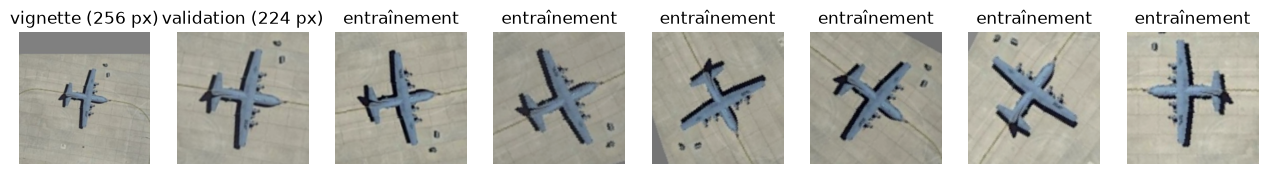

In [5]:
def for_display(tensor: torch.Tensor) -> np.ndarray:
    """Annule la normalisation ImageNet pour afficher la vignette transformée."""
    image = tensor.permute(1, 2, 0).numpy() * IMAGENET_STD + IMAGENET_MEAN
    return image.clip(0, 1)


random.seed(0)
torch.manual_seed(0)
vignette = Image.open(CROPS_DIR / index.loc[index["split"] == "train", "crop_path"].iloc[0])
fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
axes[0].imshow(vignette)
axes[0].set_title("vignette (256 px)")
axes[1].imshow(for_display(eval_transform()(vignette)))
axes[1].set_title("validation (224 px)")
for ax in axes[2:]:
    ax.imshow(for_display(train_transform()(vignette)))
    ax.set_title("entraînement")
for ax in axes:
    ax.axis("off")
plt.show()

## 3. Le réseau : un ResNet-18 pré-entraîné

Le ResNet-18 d'origine se termine par une couche à **1 000 sorties** (les 1 000
catégories d'ImageNet). On la remplace par une couche neuve à **20 sorties**, une par
type d'avion. Tout le reste du réseau (le *backbone*) garde ce qu'il a appris sur
ImageNet.

In [6]:
def build_model(pretrained: bool) -> nn.Module:
    """ResNet-18 avec une sortie par type d'avion (20) au lieu des 1000 classes d'ImageNet."""
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))  # nouvelle « tête » à 20 sorties
    return model


def load_classifier(path: Path, device: str = "cpu") -> nn.Module:
    """Recrée le réseau, puis charge les poids appris pendant l'entraînement."""
    checkpoint = torch.load(path, map_location=device, weights_only=True)
    model = build_model(pretrained=False)  # les poids viennent du fichier, pas d'ImageNet
    model.load_state_dict(checkpoint["state_dict"])
    return model.to(device).eval()


model = build_model(pretrained=False)  # ici, juste pour regarder sa structure
n_parametres = sum(p.numel() for p in model.parameters())
print(f"{n_parametres / 1e6:.1f} millions de paramètres")
print("Dernière couche :", model.fc)

11.2 millions de paramètres
Dernière couche : Linear(in_features=512, out_features=20, bias=True)


## 4. L'entraînement

À chaque **epoch**, on parcourt toutes les vignettes d'entraînement par paquets de 64 :
1. le réseau prédit un type pour chaque vignette ;
2. on mesure l'erreur, la **loss** ;
3. on calcule dans quel sens corriger chaque poids (le **gradient**) et on corrige un
   peu : c'est la **descente de gradient** (optimiseur AdamW).

Puis on mesure la macro-F1 sur la **validation**, on garde le meilleur modèle, et on
s'arrête si la validation ne progresse plus pendant 5 epochs (**early stopping**).

Trois précautions en plus :

| Précaution | Pourquoi |
|---|---|
| **réseau gelé pendant 3 epochs** : seule la nouvelle couche apprend | pour ne pas abîmer d'emblée ce que le backbone sait déjà |
| **poids 1 / √(nombre d'avions du type)** dans la loss | une erreur sur un type rare compte davantage (classes déséquilibrées) |
| **label smoothing** et **weight decay** | le réseau n'est jamais sûr à 100 %, et ses poids restent petits : moins de sur-apprentissage |

Mettre `ENTRAINER = True` **seulement sur Colab** (une carte graphique). Jamais sur ce PC.

In [7]:
CONFIG = {
    "name": "classifieur_resnet18",
    "epochs": 25,  # nombre maximal de passages sur les vignettes d'entraînement
    "freeze_epochs": 3,  # 3 premières epochs : seule la nouvelle couche apprend
    "patience": 5,  # early stopping si la macro-F1 de validation stagne 5 epochs
    "batch": 64,  # vignettes traitées ensemble
    "lr": 0.0003,  # taux d'apprentissage : taille des pas de la descente de gradient
    "weight_decay": 0.0001,  # pénalise les poids trop grands (limite l'overfitting)
    "label_smoothing": 0.1,  # le réseau n'est jamais sûr à 100 % (limite l'overfitting)
    "workers": 2,  # processus qui chargent les vignettes
    "seed": 0,
}


def scores(y_true, y_pred) -> dict:
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred, labels=range(len(CLASSES)), average="macro", zero_division=0
        ),
    }


def class_weights(labels: list[int]) -> torch.Tensor:
    """Poids 1 / racine(effectif) : une erreur sur une classe rare compte davantage."""
    counts = np.bincount(labels, minlength=len(CLASSES))
    weights = 1 / np.sqrt(counts)
    return torch.tensor(weights / weights.mean(), dtype=torch.float32)


def set_backbone_trainable(model: nn.Module, trainable: bool) -> None:
    """Gèle (trainable=False) ou dégèle tout le réseau sauf sa dernière couche."""
    for parameter in model.parameters():
        parameter.requires_grad = trainable
    for parameter in model.fc.parameters():
        parameter.requires_grad = True


def train_one_epoch(model, loader, criterion, optimizer, scaler, device) -> float:
    model.train()
    total_loss, total = 0.0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        # Sur carte graphique, calcul en demi-précision : plus rapide, même résultat
        with torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
            loss = criterion(model(images), labels)  # 1. prédiction et erreur
        scaler.scale(loss).backward()  # 2. gradient de l'erreur par rapport à chaque poids
        scaler.step(optimizer)  # 3. correction des poids
        scaler.update()
        total_loss += loss.item() * len(labels)
        total += len(labels)
    return total_loss / total


@torch.no_grad()
def evaluate(model, loader, device, criterion=None):
    """Loss moyenne (si criterion est donné), vraies classes, classes prédites et confiances."""
    model.eval()
    total_loss, y_true, y_pred, confidence = 0.0, [], [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        if criterion is not None:
            total_loss += criterion(logits, labels).item() * len(labels)
        probabilities = logits.softmax(dim=1).cpu()
        y_true.append(labels.cpu())
        y_pred.append(probabilities.argmax(dim=1))
        confidence.append(probabilities.max(dim=1).values)
    y_true = torch.cat(y_true).numpy()
    return (
        total_loss / len(y_true),
        y_true,
        torch.cat(y_pred).numpy(),
        torch.cat(confidence).numpy(),
    )


def entrainer(config: dict) -> None:
    random.seed(config["seed"])
    np.random.seed(config["seed"])
    torch.manual_seed(config["seed"])
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    train_index, val_index = load_crops_index("train"), load_crops_index("val")
    train_loader = DataLoader(
        CropDataset(train_index, train_transform()),
        batch_size=config["batch"],
        shuffle=True,
        num_workers=config["workers"],
    )
    val_loader = DataLoader(
        CropDataset(val_index, eval_transform()),
        batch_size=config["batch"],
        num_workers=config["workers"],
    )
    model = build_model(pretrained=True).to(device)  # poids ImageNet : transfer learning
    criterion = nn.CrossEntropyLoss(
        weight=class_weights(train_index["label"].tolist()).to(device),
        label_smoothing=config["label_smoothing"],
    )
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"]
    )
    # Le taux d'apprentissage baisse doucement au fil des epochs (courbe en cosinus)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config["epochs"])
    scaler = torch.amp.GradScaler(enabled=device.type == "cuda")

    out_dir = RUNS_DIR / config["name"]
    out_dir.mkdir(parents=True, exist_ok=True)
    best_f1, best_epoch, history, start = -1.0, 0, [], time.time()
    for epoch in range(1, config["epochs"] + 1):
        # Transfer learning : d'abord la nouvelle tête seule (backbone gelé), puis tout
        set_backbone_trainable(model, trainable=epoch > config["freeze_epochs"])
        train_loss = train_one_epoch(model, train_loader, criterion, optimizer, scaler, device)
        val_loss, y_true, y_pred, _ = evaluate(model, val_loader, device, criterion)
        scheduler.step()
        val = scores(y_true, y_pred)
        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                "val_loss": val_loss,
                "val_accuracy": val["accuracy"],
                "val_macro_f1": val["macro_f1"],
                "time": time.time() - start,
            }
        )
        print(
            f"epoch {epoch:2d} | loss {train_loss:.3f} | macro-F1 validation {val['macro_f1']:.3f}"
        )
        pd.DataFrame(history).to_csv(out_dir / "results.csv", index=False)
        if val["macro_f1"] > best_f1:  # meilleur modèle jusqu'ici : on le garde
            best_f1, best_epoch = val["macro_f1"], epoch
            torch.save(
                {"state_dict": model.state_dict(), "classes": CLASSES, "config": config},
                MODELS_DIR / f"{config['name']}.pt",
            )
        elif epoch - best_epoch >= config["patience"]:
            print(f"Early stopping : pas de progrès depuis {config['patience']} epochs.")
            break
    print(f"Meilleure epoch : {best_epoch} | macro-F1 en validation : {best_f1:.3f}")


ENTRAINER = False

if ENTRAINER:
    entrainer(CONFIG)
else:
    print(
        "Entraînement déjà fait sur Colab. Modèle utilisé :", MODELS_DIR / "classifieur_resnet18.pt"
    )

Entraînement déjà fait sur Colab. Modèle utilisé : C:\Users\deror\Desktop\projet_ia\models\classifieur_resnet18.pt


## 5. Les courbes d'apprentissage

L'entraînement sur Colab a enregistré les scores de chaque epoch dans
`runs/classifieur_resnet18/results.csv`. La zone grise correspond aux 3 epochs où le
réseau était gelé : seule la nouvelle couche apprenait, et la macro-F1 restait basse.
Dès que tout le réseau apprend (epoch 4), elle bondit.

14 epochs (arrêt anticipé), meilleure epoch : 9


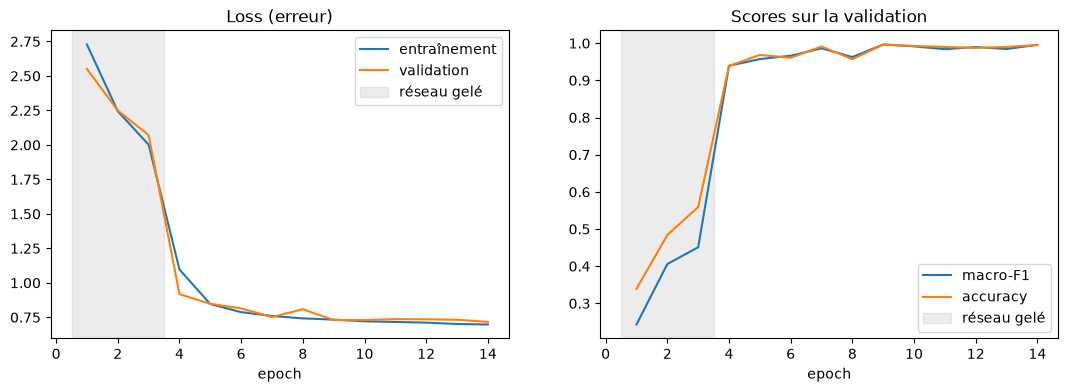

In [8]:
history = pd.read_csv(RUNS_DIR / "classifieur_resnet18" / "results.csv")
best = history.loc[history["val_macro_f1"].idxmax()]
print(f"{len(history)} epochs (arrêt anticipé), meilleure epoch : {int(best['epoch'])}")

fig, (ax_loss, ax_score) = plt.subplots(1, 2, figsize=(13, 4))
ax_loss.plot(history["epoch"], history["train_loss"], label="entraînement")
ax_loss.plot(history["epoch"], history["val_loss"], label="validation")
ax_loss.set_title("Loss (erreur)")
ax_score.plot(history["epoch"], history["val_macro_f1"], label="macro-F1")
ax_score.plot(history["epoch"], history["val_accuracy"], label="accuracy")
ax_score.set_title("Scores sur la validation")
for ax in (ax_loss, ax_score):
    ax.axvspan(0.5, CONFIG["freeze_epochs"] + 0.5, color="gray", alpha=0.15, label="réseau gelé")
    ax.set_xlabel("epoch")
    ax.legend()
plt.show()

## 6. Le classifieur sur la validation

On recharge le modèle final et on le mesure à nouveau sur les 787 vignettes de
**validation**, sur le processeur (une trentaine de secondes).

In [9]:
classifier = load_classifier(MODELS_DIR / "classifieur_resnet18.pt")
val_index = load_crops_index("val")
val_loader = DataLoader(CropDataset(val_index, eval_transform()), batch_size=64)
_, y_true, y_pred, confidence = evaluate(classifier, val_loader, "cpu")

erreurs = np.flatnonzero(y_true != y_pred)
val_scores = scores(y_true, y_pred)
print(f"accuracy : {val_scores['accuracy']:.3f}")
print(f"macro-F1 : {val_scores['macro_f1']:.3f}")
print(f"erreurs  : {len(erreurs)} sur {len(y_true)} vignettes")

accuracy : 0.996
macro-F1 : 0.996
erreurs  : 3 sur 787 vignettes


La **matrice de confusion** croise les vrais types (en lignes) et les types prédits (en
colonnes). Chaque ligne est en proportion : la diagonale donne, pour chaque type, la
part des avions bien reconnus.

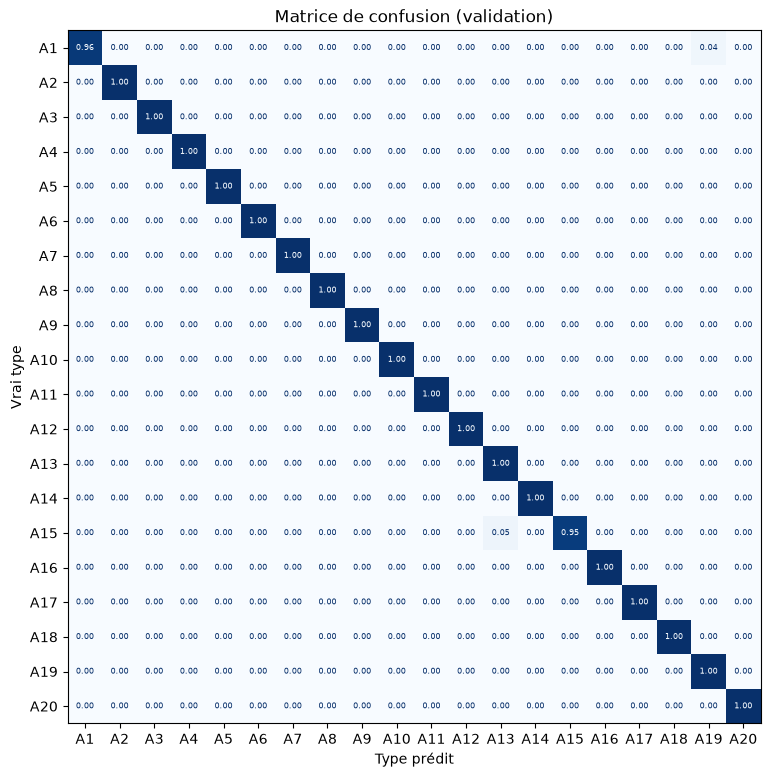

In [10]:
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=range(len(CLASSES)),
    display_labels=CLASSES,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
for text in ax.texts:
    text.set_fontsize(6)
ax.set_xlabel("Type prédit")
ax.set_ylabel("Vrai type")
ax.set_title("Matrice de confusion (validation)")
plt.show()

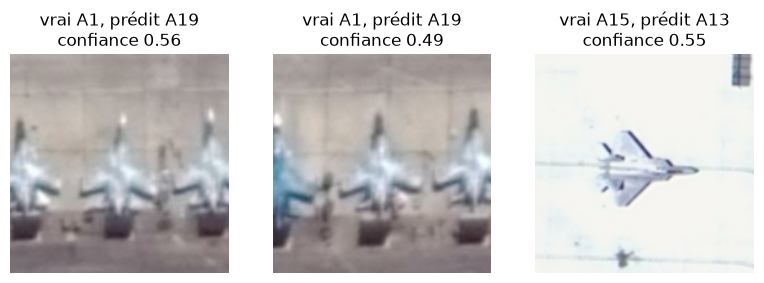

Confiance médiane sur les vignettes bien classées : 0.89


In [11]:
# Les vignettes mal classées, avec la confiance du réseau
fig, axes = plt.subplots(1, len(erreurs), figsize=(3.2 * len(erreurs), 3.4), squeeze=False)
for ax, i in zip(axes[0], erreurs, strict=True):
    ax.imshow(Image.open(CROPS_DIR / val_index.loc[i, "crop_path"]))
    ax.set_title(
        f"vrai {CLASSES[y_true[i]]}, prédit {CLASSES[y_pred[i]]}\nconfiance {confidence[i]:.2f}"
    )
    ax.axis("off")
plt.show()
print(
    f"Confiance médiane sur les vignettes bien classées : {np.median(confidence[y_true == y_pred]):.2f}"
)

## 7. Pourquoi ce modèle : la comparaison

Avant de retenir le ResNet-18 pré-entraîné, on a entraîné trois autres classifieurs,
avec les mêmes vignettes. Leurs scores ont été enregistrés dans `runs/` :

| Modèle | Idée |
|---|---|
| **forêt aléatoire** | des arbres de décision sur des descripteurs faits à la main (forme HOG + taille de la boîte) : le modèle de base |
| **petit CNN** | un réseau de neurones convolutif maison, appris de zéro |
| **ResNet-18 sans pré-entraînement** | le même réseau, mais avec des poids au hasard : mesure l'apport du transfer learning |
| **ResNet-18 pré-entraîné** | notre choix |

Le test n'a été mesuré **qu'une seule fois**, à la fin : on relit ici les scores
enregistrés, sans les recalculer.

In [12]:
import json

noms = {
    "baseline_rf": "forêt aléatoire",
    "classifieur_smallcnn": "petit CNN",
    "classifieur_resnet18_sans_pretrain": "ResNet-18 sans pré-entraînement",
    "classifieur_resnet18": "ResNet-18 pré-entraîné (retenu)",
}
val = json.loads((RUNS_DIR / "classifieurs_val" / "metrics.json").read_text(encoding="utf-8"))
test = json.loads((RUNS_DIR / "classifieurs_test" / "metrics.json").read_text(encoding="utf-8"))
pd.DataFrame(
    {
        "macro-F1 validation": {noms[k]: v["macro_f1"] for k, v in val.items()},
        "macro-F1 test": {noms[k]: v["macro_f1"] for k, v in test.items()},
        "erreurs sur le test (788)": {noms[k]: v["erreurs"] for k, v in test.items()},
    }
).reindex(noms.values()).round(3)

,macro-F1 validation,macro-F1 test,erreurs sur le test (788)
forêt aléatoire,0.614,0.625,260
petit CNN,0.690,0.567,286
ResNet-18 sans pré-entraînement,0.973,0.949,44
ResNet-18 pré-entraîné (retenu),0.996,0.958,30


Ce qu'on en retire :
- **la forêt aléatoire** apprend ses exemples par cœur (score parfait sur le train,
  0,61 en validation) : c'est du **sur-apprentissage** ;
- **le petit CNN** n'arrive même pas à bien apprendre son train : c'est du
  **sous-apprentissage**, il est trop simple ;
- **le transfer learning** apporte un point de macro-F1 et divise les erreurs
  par 1,5 sur le test (30 au lieu de 44).

## 8. Ce qu'il faut retenir

- **CNN + transfer learning** : un ResNet-18 qui sait déjà voir, dont on ne remplace
  que la dernière couche.
- **Data augmentation** adaptée aux images vues du ciel.
- **Classes déséquilibrées** : poids dans la loss, et macro-F1 pour juger.
- **Early stopping** sur la validation, jamais sur le test.

Suite : **étape 5, l'intégration**.